In [1]:
# Descriptive statistics and stationarity tests: Table 1, Figure 1, Tables A.2 and A.3, Figure A.1
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.tsa.vector_ar.var_model import VAR

warnings.filterwarnings("ignore")      # KPSS warns when its p-value is above 0.10 (shown as > 0.10)
os.makedirs("output", exist_ok=True)

# Plot style for the thesis figures
plt.rcParams.update({
    "font.family": "serif", "font.serif": ["Times New Roman", "Liberation Serif", "DejaVu Serif"],
    "mathtext.fontset": "dejavuserif", "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False, "axes.axisbelow": True,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": "#e6e5e0", "grid.linewidth": 0.6,
    "legend.frameon": False, "savefig.dpi": 300,
})
blue, orange, green, grey, red = "#2a78d6", "#eb6834", "#1baf7a", "#52514e", "#8b1a1a"

In [2]:
# Merge the clean files into one monthly data set, December 2015 to December 2025 (121 months)
files = ["spy_clean.csv", "rsp_clean.csv", "voo_clean.csv", "vix_clean.csv", "dgs10_clean.csv",
         "AIStocks_ASVI8_Monthly.csv", "AIStocks_ASVI4_Monthly.csv",
         "mag7_clean.csv", "mag7b_clean.csv", "mag7c_clean.csv"]
df = pd.read_csv(files[0], parse_dates=["date"])
for f in files[1:]:
    df = df.merge(pd.read_csv(f, parse_dates=["date"]), on="date", how="inner")
df = df.sort_values("date").reset_index(drop=True)

# 2021-2025 subsample. December 2020 only serves as the first lag, so the VARs run on Jan 2021 to Dec 2025.
sub = df[df["date"] >= "2020-12-31"].reset_index(drop=True)
print(len(df), "months,", df["date"].min().date(), "to", df["date"].max().date())

labels = {"dlog_vix": "dlogVIX", "d_dgs10": "dDGS10", "ASVI8": "ASVI8", "ASVI4": "ASVI4",
          "flow_spy": "Flow SPY", "flow_rsp": "Flow RSP", "flow_voo": "Flow VOO",
          "mag7_ret": "Mag7 returns", "mag7b_ret": "Mag7B returns", "mag7c_ret": "Mag7C returns"}

121 months, 2015-12-31 to 2025-12-31


In [3]:
# Table 1
# AR(1) is the first-order autocorrelation. Own lag is the coefficient on the variable's own first lag in
# the five-variable VAR(1): VAR-SPY, VAR-RSP or VAR-VOO for the flows, and the ASVI4 version for ASVI4.
var_spy = VAR(df[["dlog_vix", "d_dgs10", "ASVI8", "flow_spy", "mag7_ret"]]).fit(1)
var_rsp = VAR(df[["dlog_vix", "d_dgs10", "ASVI8", "flow_rsp", "mag7_ret"]]).fit(1)
var_voo = VAR(df[["dlog_vix", "d_dgs10", "ASVI8", "flow_voo", "mag7_ret"]]).fit(1)
var_asvi4 = VAR(df[["dlog_vix", "d_dgs10", "ASVI4", "flow_spy", "mag7_ret"]]).fit(1)

own_lag = {c: var_spy.params.loc["L1." + c, c] for c in var_spy.names}
own_lag["flow_rsp"] = var_rsp.params.loc["L1.flow_rsp", "flow_rsp"]
own_lag["flow_voo"] = var_voo.params.loc["L1.flow_voo", "flow_voo"]
own_lag["ASVI4"] = var_asvi4.params.loc["L1.ASVI4", "ASVI4"]

table1_vars = ["dlog_vix", "d_dgs10", "ASVI8", "ASVI4", "flow_spy", "flow_rsp", "flow_voo", "mag7_ret"]
table1 = pd.DataFrame([{
    "Variable": labels[c], "Mean": df[c].mean(), "SD": df[c].std(), "Min": df[c].min(), "Max": df[c].max(),
    "AR(1)": df[c].autocorr(1), "Own lag (VAR)": own_lag[c], "N": len(df),
} for c in table1_vars]).round(3)
table1.to_csv("output/Table_1_descriptive_statistics.csv", index=False)
table1

,Variable,Mean,SD,Min,Max,AR(1),Own lag (VAR),N
0,dlogVIX,-0.001,0.232,-0.614,0.756,-0.293,-0.180,121
1,dDGS10,0.016,0.242,-0.520,0.680,0.092,0.100,121
2,ASVI8,0.230,0.552,-0.693,2.398,0.794,0.771,121
3,ASVI4,0.103,0.475,-0.693,1.992,0.637,0.627,121
4,Flow SPY,0.001,0.027,-0.067,0.094,-0.220,-0.236,121
5,Flow RSP,0.009,0.034,-0.111,0.147,0.388,0.316,121
6,Flow VOO,0.014,0.016,-0.036,0.064,0.028,0.007,121
7,Mag7 returns,0.023,0.074,-0.197,0.200,-0.014,-0.126,121


In [4]:
print(f"ASVI8 autocorrelation: {df['ASVI8'].autocorr(1):.2f} (full sample), {sub['ASVI8'].autocorr(1):.2f} (2021-2025)")

m = df.set_index("date")["mag7_ret"]
print("Largest Mag7 gains:", ", ".join(f"{v:+.1%} ({d:%b %Y})" for d, v in m.nlargest(3).items()))
print("Largest Mag7 losses:", ", ".join(f"{v:+.1%} ({d:%b %Y})" for d, v in m.nsmallest(2).items()))

a = df.set_index("date")["ASVI8"]
after = a.loc["2022-12-31":]
print(f"ASVI8 peak: {a.max():.2f} in {a.idxmax():%B %Y}")
print(f"ASVI8 above zero from December 2022 until {after[after <= 0].index[0] - pd.offsets.MonthEnd(1):%B %Y}")

ASVI8 autocorrelation: 0.79 (full sample), 0.83 (2021-2025)
Largest Mag7 gains: +20.0% (Aug 2020), +19.5% (Apr 2020), +18.6% (Jan 2023)
Largest Mag7 losses: -19.7% (Apr 2022), -15.0% (Dec 2022)
ASVI8 peak: 2.40 in February 2023
ASVI8 above zero from December 2022 until August 2023


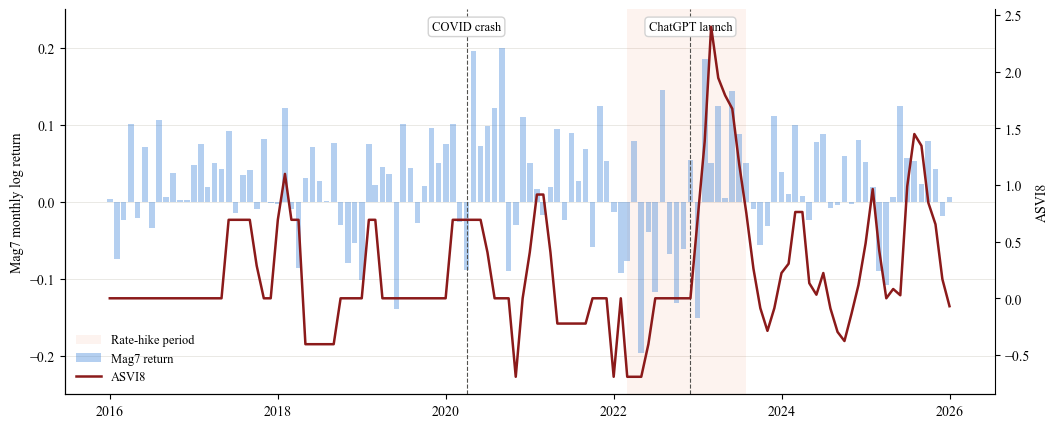

In [5]:
# Figure 1: Mag7 returns (bars, left axis) and ASVI8 (line, right axis)
fig, ax1 = plt.subplots(figsize=(12, 5))
ax1.axvspan(pd.Timestamp("2022-03-01"), pd.Timestamp("2023-07-31"), color=orange, alpha=0.08, lw=0,
            label="Rate-hike period")
ax1.bar(df["date"], df["mag7_ret"], width=25, color=blue, alpha=0.35, label="Mag7 return")
ax1.set_ylabel("Mag7 monthly log return")
ax1.set_ylim(-0.25, 0.25)

ax2 = ax1.twinx()
ax2.plot(df["date"], df["ASVI8"], color=red, lw=1.8, label="ASVI8")
ax2.set_ylabel("ASVI8")
ax2.spines["right"].set_visible(True)
ax2.grid(False)

for date, text in [("2020-03-31", "COVID crash"), ("2022-11-30", "ChatGPT launch")]:
    ax1.axvline(pd.Timestamp(date), color=grey, ls="--", lw=0.8)
    ax1.text(pd.Timestamp(date), 0.235, text, ha="center", va="top", fontsize=9,
             bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="lightgrey"))

handles = ax1.get_legend_handles_labels()[0] + ax2.get_legend_handles_labels()[0]
ax1.legend(handles, [h.get_label() for h in handles], loc="lower left", fontsize=9)
fig.savefig("output/Figure_1_ASVI8_and_Mag7_returns.png", dpi=300, bbox_inches="tight")
plt.show()

In [6]:
# Table A.2: ADF (constant, lags by AIC, H0: unit root) and KPSS (level, H0: stationary)
rows = []
for c in table1_vars + ["mag7b_ret", "mag7c_ret"]:
    adf = adfuller(df[c], autolag="AIC")
    kp = kpss(df[c], regression="c", nlags="auto")
    rows.append({"Variable": labels[c],
                 "ADF statistic": f"{adf[0]:.3f}",
                 "ADF p": "< 0.001" if adf[1] < 0.001 else f"{adf[1]:.3f}",
                 "ADF lags": adf[2],
                 "KPSS statistic": f"{kp[0]:.3f}",
                 "KPSS p": "> 0.10" if kp[1] >= 0.10 else f"{kp[1]:.3f}",     # statsmodels stops at 0.10
                 "KPSS bandwidth": kp[2]})
tableA2 = pd.DataFrame(rows)
tableA2.to_csv("output/Table_A2_stationarity.csv", index=False)
tableA2

,Variable,ADF statistic,ADF p,ADF lags,KPSS statistic,KPSS p,KPSS bandwidth
0,dlogVIX,-14.697,< 0.001,0,0.049,> 0.10,5
1,dDGS10,-9.892,< 0.001,0,0.139,> 0.10,2
2,ASVI8,-5.023,< 0.001,2,0.199,> 0.10,5
3,ASVI4,-7.322,< 0.001,1,0.144,> 0.10,4
4,Flow SPY,-10.094,< 0.001,1,0.133,> 0.10,11
5,Flow RSP,-7.206,< 0.001,0,0.238,> 0.10,3
6,Flow VOO,-9.747,< 0.001,1,0.179,> 0.10,6
7,Mag7 returns,-11.013,< 0.001,0,0.055,> 0.10,0
8,Mag7B returns,-10.807,< 0.001,0,0.051,> 0.10,2
9,Mag7C returns,-10.537,< 0.001,0,0.056,> 0.10,3


In [7]:
# Table A.3: the three return baskets
constituents = {"mag7_ret": "AAPL, AMZN, GOOGL, META, MSFT, NVDA, TSLA",
                "mag7b_ret": "Mag7 excluding TSLA", "mag7c_ret": "NVDA, MSFT, GOOGL, META"}
tableA3 = pd.DataFrame([{
    "Basket": labels[c], "Constituents": constituents[c], "Mean": df[c].mean(), "SD": df[c].std(),
    "Min": df[c].min(), "Max": df[c].max(), "AR(1)": df[c].autocorr(1),
} for c in constituents]).round(3)
tableA3.to_csv("output/Table_A3_return_baskets.csv", index=False)
print(df[list(constituents)].corr().round(3))
tableA3

           mag7_ret  mag7b_ret  mag7c_ret
mag7_ret      1.000      0.959      0.914
mag7b_ret     0.959      1.000      0.974
mag7c_ret     0.914      0.974      1.000


,Basket,Constituents,Mean,SD,Min,Max,AR(1)
0,Mag7 returns,"AAPL, AMZN, GOOGL, META, MSFT, NVDA, TSLA",0.023,0.074,-0.197,0.200,-0.014
1,Mag7B returns,Mag7 excluding TSLA,0.022,0.068,-0.194,0.161,0.005
2,Mag7C returns,"NVDA, MSFT, GOOGL, META",0.024,0.072,-0.198,0.164,0.030


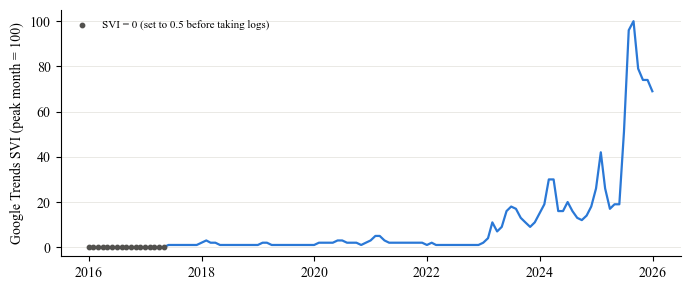

In [8]:
# Figure A.1: raw Google Trends index
svi = pd.read_csv("AIStocks_SVI_Monthly.csv", parse_dates=["date"])
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.plot(svi["date"], svi["SVI"], color=blue, lw=1.6)
zero = svi[svi["SVI"] == 0]
ax.scatter(zero["date"], zero["SVI"], s=10, color=grey, zorder=3, label="SVI = 0 (set to 0.5 before taking logs)")
ax.set_ylabel("Google Trends SVI (peak month = 100)")
ax.set_ylim(-4, 105)
ax.legend(fontsize=8, loc="upper left")
fig.savefig("output/Figure_A1_raw_SVI.png", dpi=300, bbox_inches="tight")
plt.show()